In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import json
import pandas as pd
import itertools
import shutil
import scipy.sparse as sp
from typing import Dict, Tuple, Any
from tqdm import tqdm
import itertools

from Components.Model import IrrigationSchedulingModel, IrrigationSchedulingCostQuadraticYield, IrrigationSchedulingCostLinearYield
from Components.Solver import fbrs

In [3]:
# Reload scripts when executed
%load_ext autoreload
%autoreload 2
np.set_printoptions(linewidth=np.inf)

In [4]:
parameter_file = "/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/Components/Setup/two_wells_analysis_quadCost_parameters_var.json"
crops = np.array([[1., 1.], [0., 0.], [0., 0.], [0., 0.]])

# Construct model

In [5]:
model = IrrigationSchedulingModel(parameter_file, boundary_condition="Constant Head")
quad_cost = IrrigationSchedulingCostQuadraticYield(parameter_file, model, crops)
lin_cost = IrrigationSchedulingCostLinearYield(parameter_file, model, crops)

### Check coefficient computation

In [ ]:
quad_cost.get_cost_matrices(0,1)
quad_cost.Ri_v[0], quad_cost.Li_v[0]

([array([[ 0.00081633, -0.        , -0.        , -0.        ],
         [-0.        , -0.        , -0.        , -0.        ],
         [-0.        , -0.        , -0.        , -0.        ],
         [-0.        , -0.        , -0.        , -0.        ]])],
 [array([[5.71428571, 0.        , 0.        , 0.        ]])])

In [ ]:
-2*((1/(0.7*5)**2)*(1-0.95)/((1-0.9)**2))/1000, 2*2*(1/(0.7*5))*(1-0.95)/((1-0.9)**2)

(-0.0008163265306122459, 5.7142857142857215)

In [ ]:
lin_cost.get_cost_matrices(0,1)
lin_cost.Ri_v[0], lin_cost.Li_v[0]

([array([[0., 0., 0., 0.],
         [0., 0., 0., 0.],
         [0., 0., 0., 0.],
         [0., 0., 0., 0.]])],
 [array([[0.57142857, 0.        , 0.        , 0.        ]])])

In [ ]:
2*1./(0.7*5)

0.5714285714285714

# Study of the influence of parameters on static equilibrium

Parameters to vary:
- Land size
- Selling price of crops
- Electricity price
- Crop irrigation sensitivity, maximum yield, maximum irrigation demand
- Linear vs quadratic cost parameter
- Asymmetries ?

Observation:
- Equilibrium policy

Objective:
- Having a policy sensible to a change in pumping cost
- Keeping an irrigation bellow the maximum requirement

What changes with coupling constraints?

In [ ]:
parameters_set = {
    "land_size" : [(10,10), (10, 1000), (100, 100), (1000, 1000)],
    "selling_price": [0.1, 1, 2, 5, 10, 50, 100],
    "max_yield": [0.1, 0.5, 1, 2, 10],
    "max_Kc": [0.1, 0.5, 0.7, 1, 2, 10],
    "intermediate_yield": [0.9, 0.91, 0.92, 0.95, 0.96, 0.97, 0.98, 0.99],
    "alpha_price": [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1],
    "electricity_price": [0.1, 0.5, 1, 2, 5, 10, 100]
}

In [ ]:
# dir, file = os.path.split(parameter_file)
# name, ext = file.split('.')
# new_parameter_file = dir + '/' + name + '_tmp' + '.' + ext

## Construct Data

In [ ]:
keys = list(parameters_set.keys())
values = list(parameters_set.values())

rows = list(itertools.product(*values))
df = pd.DataFrame(rows, columns=keys)

# print(df.loc[(df['land_size'] == (10,10)) & (df['selling_price'] == 0.1) & (df['max_yield'] == 0.1)])

In [ ]:
_, a, _, _, _ = lin_cost.get_cost_matrices(0,1)
(np.array(a)[:,0,...] + np.array(a)[:,0,...]).shape

(2, 4, 4)

In [ ]:
# # df["q_opt_0"] = np.nan
# # df["q_opt_1"] = np.nan

# pbar = tqdm(total=(len(df)),
#                 position=0, desc="Scenario", leave=True)
# for r in df.iterrows():
#     # print(r[1])
#     if not np.isnan(df.loc[r[0], 'q_opt_0']):
#         continue
#     shutil.copyfile(parameter_file, new_parameter_file)
#     with open(new_parameter_file, 'r+') as f:
#         data = json.load(f)
#         # modify fields
#         data['land']['surface'] = list(r[1]['land_size'])
#         data['costs']['selling_crop_price'] = [r[1]['selling_price'], r[1]['selling_price'], r[1]['selling_price'], r[1]['selling_price']]
#         data['crops']['corn']['Y_max_t'][0] = r[1]['max_yield']
#         data['crops']['corn']['Kc_t'] = [r[1]['max_Kc'], r[1]['max_Kc']]
#         data['crops']['corn']['Y_intermediate_t'][0] = r[1]['intermediate_yield']
#         data['costs']['extraction_cost'] = [r[1]['electricity_price'], r[1]['electricity_price']]
#         # overwrite file
#         f.seek(0)
#         json.dump(data, f, indent=4)
#         f.truncate()
#     # Construct model
#     model = IrrigationSchedulingModel(new_parameter_file, boundary_condition="Constant Head")
#     quad_cost = IrrigationSchedulingCostQuadraticYield(new_parameter_file, model, crops)
#     lin_cost = IrrigationSchedulingCostLinearYield(new_parameter_file, model, crops)
#     # Construct cost matrices
#     Q_quad, R_v_quad, R_v_minus_quad, M_v_quad, L_v_quad = quad_cost.get_cost_matrices(0,1)
#     Q_lin,  R_v_lin,  R_v_minus_lin,  M_v_lin,  L_v_lin  = lin_cost.get_cost_matrices(0,1)
#     for alpha in parameters_set["alpha_price"]:
#         R_v, R_v_minus, M_v, L_v =  \
#             alpha*np.array(R_v_quad)[:,0,...] + (1-alpha)*np.array(R_v_lin)[:,0,...], \
#             alpha*np.array(R_v_minus_quad)[:,0,...] + (1-alpha)*np.array(R_v_minus_lin)[:,0,...], \
#             alpha*np.array(M_v_quad)[:,0,...] + (1-alpha)*np.array(M_v_lin)[:,0,...], \
#             alpha*np.array(L_v_quad)[:,0,...] + (1-alpha)*np.array(L_v_lin)[:,0,...]
#         # Compute equilibrium optimal command - Form cost matrices
#         F = sp.block_array([
#             [sp.csr_array((R_v[0,:,:] + model.B_v[0].T @ (np.linalg.inv(np.eye(model.A.shape[0])-model.A)).T @ M_v[0]) + \
#                 (R_v[0,:,:] + model.B_v[0].T @ (np.linalg.inv(np.eye(model.A.shape[0])-model.A)).T @ M_v[0]).T), 
#              sp.csr_array((R_v_minus[0] + model.B_v[1].T @ (np.linalg.inv(np.eye(model.A.shape[0])-model.A)).T @ M_v[0]).T)],
#             [sp.csr_array((R_v_minus[1] + model.B_v[0].T @ (np.linalg.inv(np.eye(model.A.shape[0])-model.A)).T @ M_v[1]).T),
#              sp.csr_array((R_v[1, :, :] + model.B_v[1].T @ (np.linalg.inv(np.eye(model.A.shape[0])-model.A)).T @ M_v[1]) + \
#                 (R_v[1, :, :] + model.B_v[1].T @ (np.linalg.inv(np.eye(model.A.shape[0])-model.A)).T @ M_v[1]).T)]
#         ])
#         f = np.vstack([
#             (L_v[0] + model.C.T @ (np.linalg.inv(np.eye(model.A.shape[0])-model.A)).T @ M_v[0]).T,
#             (L_v[1] + model.C.T @ (np.linalg.inv(np.eye(model.A.shape[0])-model.A)).T @ M_v[1]).T
#         ])
#         # Construct constraint matrices
#         H = np.vstack([
#             sp.block_diag(model.H_u_v).toarray(),
#             # model.H_x @ (np.linalg.inv(np.eye(model.A.shape[0])-model.A)) @ sp.hstack(model.B_v)
#         ])
#         h = np.vstack([
#             sp.vstack(model.h_u_v).toarray(),
#             # model.h_x.toarray() - (np.linalg.inv(np.eye(model.A.shape[0])-model.A)) @ model.C
#         ])
#         # Find equilibrium
#         u_s_0 = np.zeros((8, 1))
#         dual_0 = np.zeros((H.shape[0], 1))
#         U_opt, dual, E, out = fbrs(F, f, H, h, u_s_0, dual_0)
#         # print(U_opt)
#         df.loc[r[0], 'q_opt_0'] = U_opt[0]
#         df.loc[r[0], 'q_opt_1'] = U_opt[4]
#         pbar.update(1)
#         # break
#     # break
# print(df)

In [ ]:
Ymax_v_c_t = quad_cost._yield_max([0])
ETmax_v_c_t = quad_cost._local_evapotranspiration([0]).T
Y_q_v_c_t = quad_cost._yield_intermediate([0])
def _get_yield_response_to_water_coefficients(settings: Dict[str, Any]) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """ Coefficients of the quadratic function. """
    # Get yield data
    Ymax_v_c_t[0,0] = settings['max_yield']         # [n_crop, horizon]
    ETmax_v_c_t[0,0] = settings['max_Kc']*5         # [n_crop, horizon]
    Y_q_v_c_t[0,0] = settings['intermediate_yield'] # [n_crop, horizon]
    # Safely inverse values
    inv_ETmax_v_c_t = np.where(ETmax_v_c_t !=0, 1/ETmax_v_c_t, 0)
    inv_quad_ETmax_v_c_t = np.where(ETmax_v_c_t !=0, 1/(ETmax_v_c_t**2), 0)
    # Construct local coefficients
    a_yield_v_c_t = - Ymax_v_c_t * inv_quad_ETmax_v_c_t * \
        (1 - Y_q_v_c_t)/ \
            ((1 - quad_cost.intermediate_irrigation_value)**2)
    b_yield_v_c_t = 2* Ymax_v_c_t * inv_ETmax_v_c_t * \
        (1 - Y_q_v_c_t)/ \
            ((1 - quad_cost.intermediate_irrigation_value)**2)
    c_yield_v_c_t = Ymax_v_c_t * (1 - \
        (1 - Y_q_v_c_t)/ \
            ((1 - quad_cost.intermediate_irrigation_value)**2))
    # Scale to obtain global coefficients
    if type(settings['land_size']) == str:
        land_surface = np.array(eval(settings['land_size']))
    else:
        land_surface = np.array(settings['land_size'])
    crop_surface = (land_surface * quad_cost.crop_repartition).T            # [n_agent, n_crops]
    inv_crop_surface = np.divide(np.ones_like(crop_surface), crop_surface,
                                     out=np.zeros_like(crop_surface),
                                     where=crop_surface!=0)                 # [n_agent, n_crops]
    null_surface_mask = np.where(crop_surface !=0, 1, 0)                    # [n_agent, n_crops]
    a_yield_v_c_t = inv_crop_surface[:, :, None] * a_yield_v_c_t[None, :, :]
    b_yield_v_c_t = null_surface_mask[:, :, None] * b_yield_v_c_t[None, :, :]
    c_yield_v_c_t = crop_surface[:, :, None] * c_yield_v_c_t[None, :, :]
    return a_yield_v_c_t, b_yield_v_c_t, c_yield_v_c_t                      # [n_agent, n_crops, horizon]

def _compute_irrigation_cost_matrices(settings):
    # Get cost data
    a_yield_v_c_t, b_yield_v_c_t, _ = _get_yield_response_to_water_coefficients(settings)    # [n_agent, n_crop, horizon]
    # Arrange a in square diagonal matrices of size n_crops for all v,t
    diag_a_yield_v_c_t = [sp.diags(a_yield_v_c_t[v,:,0].flatten())
                          for v in range(quad_cost.n_agent)]
    # Arrange b in flat matrices of size n_crops for all v,t
    diag_b_yield_v_c_t = [b_yield_v_c_t[v,:,0].flatten().reshape(1, quad_cost.n_crops)
                    for v in range(quad_cost.n_agent)]
    # Form cost matrices
    Ri_v = [- (settings['selling_price'] * u2c.T  @ a_yield @ u2c)
                    for u2c, a_yield in
                    zip(quad_cost.input_to_crop_irrigation_v, diag_a_yield_v_c_t)]
    Li_v = [settings['selling_price'] * b_yield @ u2c
                    for u2c, b_yield in
                    zip(quad_cost.input_to_crop_irrigation_v, diag_b_yield_v_c_t)]
    return Ri_v, Li_v

In [ ]:
def _compute_irrigation_cost_matrix(settings):
    Ymax_v_c_t[0,0] = settings['max_yield']         # [n_crop, horizon]
    ETmax_v_c_t[0,0] = settings['max_Kc']*5         # [n_crop, horizon]
    # Safely inverse values
    inv_ETmax_v_c_t = np.where(ETmax_v_c_t !=0, 1/ETmax_v_c_t, 0)
    # Construct slope
    k_yield_v_c_t = Ymax_v_c_t * inv_ETmax_v_c_t    # [n_crop, horizon]
    # Extend it to all players
    if type(settings['land_size']) == str:
        land_surface = np.array(eval(settings['land_size']))
    else:
        land_surface = np.array(settings['land_size'])
    crop_surface = land_surface[:, None] * lin_cost.crop_repartition.T    # [n_agent, n_crops]
    null_surface_mask = np.where(crop_surface !=0, 1, 0)                  # [n_agent, n_crops]
    k_yield_v_c_t = null_surface_mask[:, :, None] * k_yield_v_c_t[None, :, :]
    diag_k_yield_v_c_t = [k_yield_v_c_t[v,:,0].flatten().reshape(1, lin_cost.n_crops)
                    for v in range(lin_cost.n_agent)]
    return [settings['selling_price'] * k_yield @ u2c
                     for u2c, k_yield in
                     zip(lin_cost.input_to_crop_irrigation_v, diag_k_yield_v_c_t)]

In [ ]:
df = pd.read_csv("tmp.csv")

In [ ]:
# df["q_opt_0"] = np.nan
# df["q_opt_1"] = np.nan

In [ ]:
count = 0
pbar = tqdm(total=(len(df)),
                position=0, desc="Scenario", leave=True)
for r in df.iterrows():
    pbar.update(1)
    # print(r[1])
    if not np.isnan(df.loc[r[0], 'q_opt_0']):
        count += 1
        continue
    # Construct quadratic and linear cost matrices
    Ri_v_quad, Li_v_quad = _compute_irrigation_cost_matrices(r[1])
    Li_v_lin = _compute_irrigation_cost_matrix(r[1])
    # Scale pumping cost
    Rp_v, Rp_v_minus, Mp_v, Lp_v = r[1]['electricity_price']*np.array(quad_cost.Rp_v)/quad_cost.extraction_cost_v[0], r[1]['electricity_price']*np.array(quad_cost.Rp_v_minus)/quad_cost.extraction_cost_v[0], r[1]['electricity_price']*np.array(quad_cost.Mp_v)/quad_cost.extraction_cost_v[0], r[1]['electricity_price']*np.array(quad_cost.Lp_v)/quad_cost.extraction_cost_v[0]
    for alpha in parameters_set["alpha_price"]:
        # Construct cost matrices
        R_v, R_v_minus, M_v, L_v =  \
            alpha*np.array(Ri_v_quad) + Rp_v, \
            Rp_v_minus, \
            Mp_v, \
            alpha*np.array(Li_v_quad) + (1-alpha)*np.array(Li_v_lin) + Lp_v
        # Compute equilibrium optimal command - Form cost matrices
        F = sp.block_array([
            [sp.csr_array((R_v[0,:,:] + model.B_v[0].T @ (np.linalg.inv(np.eye(model.A.shape[0])-model.A)).T @ M_v[0]) + \
                (R_v[0,:,:] + model.B_v[0].T @ (np.linalg.inv(np.eye(model.A.shape[0])-model.A)).T @ M_v[0]).T), 
             sp.csr_array((R_v_minus[0] + model.B_v[1].T @ (np.linalg.inv(np.eye(model.A.shape[0])-model.A)).T @ M_v[0]).T)],
            [sp.csr_array((R_v_minus[1] + model.B_v[0].T @ (np.linalg.inv(np.eye(model.A.shape[0])-model.A)).T @ M_v[1]).T),
             sp.csr_array((R_v[1, :, :] + model.B_v[1].T @ (np.linalg.inv(np.eye(model.A.shape[0])-model.A)).T @ M_v[1]) + \
                (R_v[1, :, :] + model.B_v[1].T @ (np.linalg.inv(np.eye(model.A.shape[0])-model.A)).T @ M_v[1]).T)]
        ])
        f = np.vstack([
            (L_v[0] + model.C.T @ (np.linalg.inv(np.eye(model.A.shape[0])-model.A)).T @ M_v[0]).T,
            (L_v[1] + model.C.T @ (np.linalg.inv(np.eye(model.A.shape[0])-model.A)).T @ M_v[1]).T
        ])
        # Construct constraint matrices
        H = np.vstack([
            sp.block_diag(model.H_u_v).toarray(),
            # model.H_x @ (np.linalg.inv(np.eye(model.A.shape[0])-model.A)) @ sp.hstack(model.B_v)
        ])
        h = np.vstack([
            sp.vstack(model.h_u_v).toarray(),
            # model.h_x.toarray() - (np.linalg.inv(np.eye(model.A.shape[0])-model.A)) @ model.C
        ])
        # Find equilibrium
        u_s_0 = np.zeros((8, 1))
        dual_0 = np.zeros((H.shape[0], 1))
        U_opt, dual, E, out = fbrs(F, f, H, h, u_s_0, dual_0)
        # print(U_opt)
        idx = df.index[(df['land_size'] == r[1]['land_size']) & \
            (df['selling_price'] == r[1]['selling_price']) & \
                (df['max_yield'] == r[1]['max_yield']) & \
                    (df['max_Kc'] == r[1]['max_Kc']) & \
                        (df['max_yield'] == r[1]['max_yield']) & \
                            (df['intermediate_yield'] == r[1]['intermediate_yield']) & \
                                (df['alpha_price'] == alpha) & \
                                    (df['electricity_price'] == r[1]['electricity_price'])]
        df.loc[idx, 'q_opt_0'] = U_opt[0]
        df.loc[idx, 'q_opt_1'] = U_opt[4]
        # break
        if idx % 1000 == 0:
            df.to_csv("tmp.csv")
    # break
print(df)

Scenario:   0%|          | 0/517440 [00:00<?, ?it/s]0.01s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
Scenario: 100%|█████████▉| 517371/517440 [8:06:25<00:30,  2.27it/s]   

        Unnamed: 0     land_size  selling_price  max_yield  max_Kc  \
0                0      (10, 10)            0.1        0.1     0.1   
1                1      (10, 10)            0.1        0.1     0.1   
2                2      (10, 10)            0.1        0.1     0.1   
3                3      (10, 10)            0.1        0.1     0.1   
4                4      (10, 10)            0.1        0.1     0.1   
...            ...           ...            ...        ...     ...   
517435      517435  (1000, 1000)          100.0       10.0    10.0   
517436      517436  (1000, 1000)          100.0       10.0    10.0   
517437      517437  (1000, 1000)          100.0       10.0    10.0   
517438      517438  (1000, 1000)          100.0       10.0    10.0   
517439      517439  (1000, 1000)          100.0       10.0    10.0   

        intermediate_yield  alpha_price  electricity_price      q_opt_0  \
0                     0.90          0.0                0.1   -44.001584   
1        

In [ ]:
df.to_csv("tmp.csv")

## Analyze data

In [ ]:
for land_size, selling_price, max_yield, max_Kc, intermediate_yield, alpha_price \
    in itertools.product(parameters_set['land_size'],
                         parameters_set['selling_price'],
                         parameters_set['max_yield'],
                         parameters_set['max_Kc'],
                         parameters_set['intermediate_yield'],
                         parameters_set['alpha_price']):
        idx_1 = df.index[(df['land_size'] == str(land_size)) & \
            (df['selling_price'] == selling_price) & \
                (df['max_yield'] == max_yield) & \
                    (df['max_Kc'] == max_Kc) & \
                        (df['intermediate_yield'] == intermediate_yield) & \
                            (df['alpha_price'] == alpha_price) & \
                                (df['electricity_price'] == 100)]
        idx_2 = df.index[(df['land_size'] == str(land_size)) & \
            (df['selling_price'] == selling_price) & \
                (df['max_yield'] == max_yield) & \
                    (df['max_Kc'] == max_Kc) & \
                        (df['intermediate_yield'] == intermediate_yield) & \
                            (df['alpha_price'] == alpha_price) & \
                                (df['electricity_price'] == 0.1)]
        #print(df.loc[idx_1, 'q_opt_0'], df.loc[idx_2, 'q_opt_0'])
        print(abs(df.loc[idx_1, 'q_opt_0'].values[0] - df.loc[idx_2, 'q_opt_0'].values[0]))
        break

43.95758275314417


In [ ]:
def electricity_price_impact(params):
    idx_1 = df.index[(df['land_size'] == str((params[0], params[1]))) & \
            (df['selling_price'] == params[1+1]) & \
                (df['max_yield'] == params[2+1]) & \
                    (df['max_Kc'] == params[3+1]) & \
                        (df['intermediate_yield'] == params[4+1]) & \
                            (df['alpha_price'] == params[5+1]) & \
                                (df['electricity_price'] == 100)]
    idx_2 = df.index[(df['land_size'] == str((params[0], params[1]))) & \
            (df['selling_price'] == params[1+1]) & \
                (df['max_yield'] == params[2+1]) & \
                    (df['max_Kc'] == params[3+1]) & \
                        (df['intermediate_yield'] == params[4+1]) & \
                            (df['alpha_price'] == params[5+1]) & \
                            (df['electricity_price'] == 0.1)]
    #print(df.loc[idx_1, 'q_opt_0'].values[0], df.loc[idx_2, 'q_opt_0'].values[0])
    return abs(df.loc[idx_1, 'q_opt_0'].values[0] - df.loc[idx_2, 'q_opt_0'].values[0])

product = [[l[0][0], l[0][1], l[1], l[2], l[3], l[4], l[5]]
           for l in list(itertools.product(parameters_set['land_size'],
                                           parameters_set['selling_price'],
                                           parameters_set['max_yield'],
                                           parameters_set['max_Kc'],
                                           parameters_set['intermediate_yield'],
                                           parameters_set['alpha_price']))]
# for i,p in enumerate(product):
#     electricity_price_impact(p)
sorted_product = sorted(product, key=electricity_price_impact)

In [ ]:
sorted_product

[[10, 10, 100, 10, 0.1, 0.9, 1],
 [10, 10, 100, 10, 0.1, 0.91, 1],
 [10, 10, 100, 10, 0.1, 0.9, 0.9],
 [10, 10, 100, 10, 0.1, 0.91, 0.9],
 [10, 10, 100, 10, 0.1, 0.92, 1],
 [10, 10, 100, 10, 0.1, 0.9, 0.8],
 [10, 10, 100, 10, 0.1, 0.92, 0.9],
 [10, 10, 100, 10, 0.1, 0.91, 0.8],
 [10, 10, 100, 10, 0.1, 0.9, 0.7],
 [10, 10, 100, 10, 0.1, 0.92, 0.8],
 [10, 10, 100, 10, 0.1, 0.91, 0.7],
 [10, 10, 100, 10, 0.1, 0.9, 0.6],
 [10, 10, 100, 10, 0.1, 0.92, 0.7],
 [10, 10, 100, 10, 0.1, 0.91, 0.6],
 [10, 10, 50, 10, 0.1, 0.9, 1],
 [10, 10, 100, 10, 0.1, 0.95, 1],
 [10, 10, 100, 10, 0.1, 0.9, 0.5],
 [10, 10, 100, 10, 0.1, 0.92, 0.6],
 [10, 10, 50, 10, 0.1, 0.91, 1],
 [10, 10, 50, 10, 0.1, 0.9, 0.9],
 [10, 10, 100, 10, 0.1, 0.95, 0.9],
 [10, 10, 100, 10, 0.1, 0.91, 0.5],
 [10, 10, 50, 10, 0.1, 0.91, 0.9],
 [10, 10, 50, 10, 0.1, 0.92, 1],
 [10, 10, 100, 10, 0.1, 0.96, 1],
 [10, 10, 50, 10, 0.1, 0.9, 0.8],
 [10, 10, 100, 10, 0.1, 0.95, 0.8],
 [10, 10, 100, 10, 0.1, 0.92, 0.5],
 [10, 10, 100, 10, 0.1,

In [ ]:
electricity_price_impact(sorted_product[-1]), electricity_price_impact(sorted_product[0])

(np.float64(4395758.2870594105), np.float64(0.00028372214498251225))

In [ ]:
sorted_product[-1]

[1000, 1000, 100, 10, 0.1, 0.99, 0]

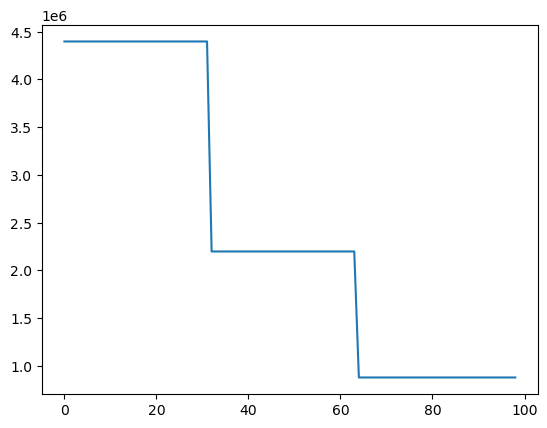

In [ ]:
plt.plot([electricity_price_impact(sorted_product[-i]) for i in range(1,100)])

In [ ]:
electricity_price_impact(sorted_product[-32]), electricity_price_impact(sorted_product[-33]), \
    electricity_price_impact(sorted_product[-64]), electricity_price_impact(sorted_product[-65])

(np.float64(4395758.2870594105),
 np.float64(2197879.1435297816),
 np.float64(2197879.1435297816),
 np.float64(879151.6574119909))

In [ ]:
(sorted_product[-32:-1])

[[10, 10, 100, 10, 0.1, 0.9, 0],
 [10, 10, 100, 10, 0.1, 0.91, 0],
 [10, 10, 100, 10, 0.1, 0.92, 0],
 [10, 10, 100, 10, 0.1, 0.95, 0],
 [10, 10, 100, 10, 0.1, 0.96, 0],
 [10, 10, 100, 10, 0.1, 0.97, 0],
 [10, 10, 100, 10, 0.1, 0.98, 0],
 [10, 10, 100, 10, 0.1, 0.99, 0],
 [10, 1000, 100, 10, 0.1, 0.9, 0],
 [10, 1000, 100, 10, 0.1, 0.91, 0],
 [10, 1000, 100, 10, 0.1, 0.92, 0],
 [10, 1000, 100, 10, 0.1, 0.95, 0],
 [10, 1000, 100, 10, 0.1, 0.96, 0],
 [10, 1000, 100, 10, 0.1, 0.97, 0],
 [10, 1000, 100, 10, 0.1, 0.98, 0],
 [10, 1000, 100, 10, 0.1, 0.99, 0],
 [100, 100, 100, 10, 0.1, 0.9, 0],
 [100, 100, 100, 10, 0.1, 0.91, 0],
 [100, 100, 100, 10, 0.1, 0.92, 0],
 [100, 100, 100, 10, 0.1, 0.95, 0],
 [100, 100, 100, 10, 0.1, 0.96, 0],
 [100, 100, 100, 10, 0.1, 0.97, 0],
 [100, 100, 100, 10, 0.1, 0.98, 0],
 [100, 100, 100, 10, 0.1, 0.99, 0],
 [1000, 1000, 100, 10, 0.1, 0.9, 0],
 [1000, 1000, 100, 10, 0.1, 0.91, 0],
 [1000, 1000, 100, 10, 0.1, 0.92, 0],
 [1000, 1000, 100, 10, 0.1, 0.95, 0],
 [10

The common values are: 
- selling_price = 100
- max_yield = 10
- max_Kc = 0.1
- alpha_price = 0

Remains 'land_size' and 'intermediate_yield': so 4x8=32 possibilities.

In [ ]:
(sorted_product[-64:-32])

[[10, 10, 50, 10, 0.1, 0.9, 0],
 [10, 10, 50, 10, 0.1, 0.91, 0],
 [10, 10, 50, 10, 0.1, 0.92, 0],
 [10, 10, 50, 10, 0.1, 0.95, 0],
 [10, 10, 50, 10, 0.1, 0.96, 0],
 [10, 10, 50, 10, 0.1, 0.97, 0],
 [10, 10, 50, 10, 0.1, 0.98, 0],
 [10, 10, 50, 10, 0.1, 0.99, 0],
 [10, 1000, 50, 10, 0.1, 0.9, 0],
 [10, 1000, 50, 10, 0.1, 0.91, 0],
 [10, 1000, 50, 10, 0.1, 0.92, 0],
 [10, 1000, 50, 10, 0.1, 0.95, 0],
 [10, 1000, 50, 10, 0.1, 0.96, 0],
 [10, 1000, 50, 10, 0.1, 0.97, 0],
 [10, 1000, 50, 10, 0.1, 0.98, 0],
 [10, 1000, 50, 10, 0.1, 0.99, 0],
 [100, 100, 50, 10, 0.1, 0.9, 0],
 [100, 100, 50, 10, 0.1, 0.91, 0],
 [100, 100, 50, 10, 0.1, 0.92, 0],
 [100, 100, 50, 10, 0.1, 0.95, 0],
 [100, 100, 50, 10, 0.1, 0.96, 0],
 [100, 100, 50, 10, 0.1, 0.97, 0],
 [100, 100, 50, 10, 0.1, 0.98, 0],
 [100, 100, 50, 10, 0.1, 0.99, 0],
 [1000, 1000, 50, 10, 0.1, 0.9, 0],
 [1000, 1000, 50, 10, 0.1, 0.91, 0],
 [1000, 1000, 50, 10, 0.1, 0.92, 0],
 [1000, 1000, 50, 10, 0.1, 0.95, 0],
 [1000, 1000, 50, 10, 0.1, 0.96,

Here we have: 
- selling_price = 50
- max_yield = 10
- max_Kc = 0.1
- alpha_price = 0

The selling price has been divided by two, which results in an electricity price impact divided by 2.

Remark: it is logical that the two parameters 'land_size' and 'intermediate_yield' have no influence here, as they don't appear in the linear cost definition.

In [ ]:
loc = (np.array(sorted_product)[-int(len(sorted_product)/len(parameters_set['alpha_price'])):, -1] != 0)
(np.array(sorted_product)[-int(len(sorted_product)/len(parameters_set['alpha_price'])):, -1]), \
    (np.array(sorted_product)[-int(len(sorted_product)/len(parameters_set['alpha_price'])):, -1])[loc]

(array([0., 0., 0., ..., 0., 0., 0.], shape=(6720,)),
 array([0.3, 0.8, 0.8, ..., 0.6, 0.5, 0.4], shape=(3809,)))

In [ ]:
np.arange(int(len(sorted_product)/len(parameters_set['alpha_price'])))[loc] - int(len(sorted_product)/len(parameters_set['alpha_price']))

array([-6369, -6368, -6367, ...,  -931,  -930,  -929], shape=(3809,))

In [ ]:
sorted_product[-929]

[1000, 1000, 100, 10, 10, 0.9, 0.4]

In [ ]:
electricity_price_impact(sorted_product[-929]), electricity_price_impact(sorted_product[-928]), electricity_price_impact(sorted_product[-930])

(np.float64(46690.22258361553),
 np.float64(62796.546957994135),
 np.float64(46685.96537655176))

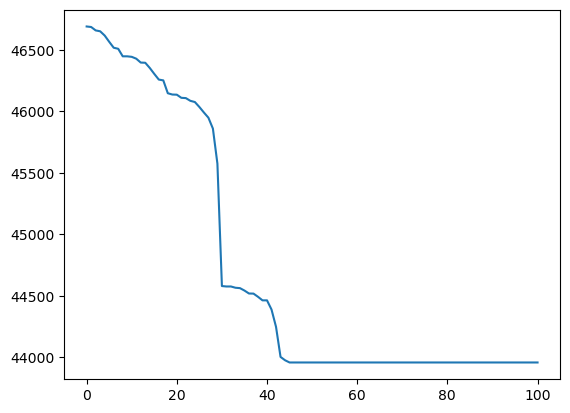

In [ ]:
plt.plot([electricity_price_impact(sorted_product[-i]) for i in range(929,1030)])

In [ ]:
electricity_price_impact(sorted_product[-929]), electricity_price_impact(sorted_product[-958]),\
    electricity_price_impact(sorted_product[-959]), electricity_price_impact(sorted_product[-971]), \
        electricity_price_impact(sorted_product[-972])

(np.float64(46690.22258361553),
 np.float64(45574.590177878665),
 np.float64(44579.147065292425),
 np.float64(44247.30233200661),
 np.float64(44002.84209812869))

In [ ]:
sorted_product[-958:-928]

[[1000, 1000, 100, 10, 10, 0.92, 0.1],
 [1000, 1000, 100, 10, 10, 0.91, 0.1],
 [1000, 1000, 100, 10, 10, 0.92, 0.2],
 [1000, 1000, 100, 10, 10, 0.92, 1],
 [1000, 1000, 100, 10, 10, 0.92, 0.9],
 [1000, 1000, 100, 10, 10, 0.92, 0.8],
 [1000, 1000, 100, 10, 10, 0.92, 0.3],
 [1000, 1000, 100, 10, 10, 0.9, 0.1],
 [1000, 1000, 100, 10, 10, 0.92, 0.7],
 [1000, 1000, 100, 10, 10, 0.92, 0.6],
 [1000, 1000, 100, 10, 10, 0.92, 0.4],
 [1000, 1000, 100, 10, 10, 0.92, 0.5],
 [1000, 1000, 100, 10, 10, 0.91, 1],
 [1000, 1000, 100, 10, 10, 0.91, 0.2],
 [1000, 1000, 100, 10, 10, 0.91, 0.9],
 [1000, 1000, 100, 10, 10, 0.91, 0.8],
 [1000, 1000, 100, 10, 10, 0.91, 0.7],
 [1000, 1000, 100, 10, 10, 0.91, 0.3],
 [1000, 1000, 100, 10, 10, 0.91, 0.6],
 [1000, 1000, 100, 10, 10, 0.91, 0.4],
 [1000, 1000, 100, 10, 10, 0.91, 0.5],
 [1000, 1000, 100, 10, 10, 0.9, 1],
 [1000, 1000, 100, 10, 10, 0.9, 0.9],
 [1000, 1000, 100, 10, 10, 0.9, 0.2],
 [1000, 1000, 100, 10, 10, 0.9, 0.8],
 [1000, 1000, 100, 10, 10, 0.9, 0.7]

The common values are: 
- land_size = (1000, 1000)
- selling_price = 100
- max_yield = 10
- max_Kc = 10

'intermediate_yield' varies between 0.9 and 0.92, and 'alpha_price' takes all values.

In [ ]:
sorted_product[-971:-958]

[[1000, 1000, 50, 10, 10, 0.9, 0.9],
 [1000, 1000, 100, 10, 10, 0.95, 0.1],
 [1000, 1000, 100, 10, 10, 0.95, 1],
 [1000, 1000, 50, 10, 10, 0.9, 1],
 [1000, 1000, 100, 10, 10, 0.95, 0.9],
 [1000, 1000, 100, 10, 10, 0.95, 0.2],
 [1000, 1000, 100, 10, 10, 0.95, 0.8],
 [1000, 1000, 100, 10, 10, 0.95, 0.7],
 [1000, 1000, 100, 10, 10, 0.95, 0.6],
 [1000, 1000, 100, 10, 10, 0.95, 0.3],
 [1000, 1000, 100, 10, 2, 0.99, 0.1],
 [1000, 1000, 100, 10, 10, 0.95, 0.5],
 [1000, 1000, 100, 10, 10, 0.95, 0.4]]

We still have as common value: 
- land_size = (1000, 1000)
- max_yield = 10

'intermediate_yield' varies between 0.9 and 0.99, and 'alpha_price' takes approximately all values.

'selling_price' = 100 in general. When it is lower (=50), 'alpha_price' has higher values (0.99 or 1).

'max_Kc' = 10 in general. When it is lower (=2) as 'intermediate_yield' has a higher value (0.99) than usual (0.95).

When 'alpha_price' has higher values (0.99 or 1) AND 'intermediate_yield' has a lower value (0.9), then 'selling_price' is lower (=50).

In [ ]:
electricity_price_impact([1000, 1000, 100, 10, 10, 0.9, 1]), \
    electricity_price_impact([1000, 1000, 50, 10, 10, 0.9, 1]), \
        electricity_price_impact([1000, 1000, 100, 10, 10, 0.95, 1])

(np.float64(46447.608981988065),
 np.float64(44462.82416814531),
 np.float64(44462.824168145286))

When alpha_price = 1, it has the same effect to divide 'selling_price' by 2 and multiply 'intermediate_yield' by 0.95/0.9 = 1.055

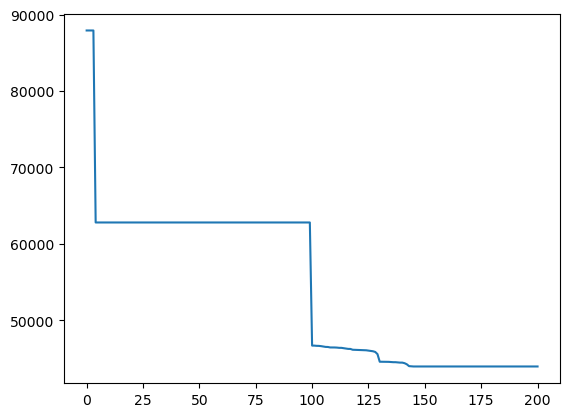

In [ ]:
plt.plot([electricity_price_impact(sorted_product[-i]) for i in range(829,1030)])

In [ ]:
electricity_price_impact(sorted_product[-832]), electricity_price_impact(sorted_product[-833]), \
    electricity_price_impact(sorted_product[-928]), electricity_price_impact(sorted_product[-929])

(np.float64(87915.16574119317),
 np.float64(62796.546957994135),
 np.float64(62796.546957994135),
 np.float64(46690.22258361553))

In [ ]:
sorted_product[-928:-832]

[[10, 10, 10, 10, 0.7, 0.9, 0],
 [10, 10, 10, 10, 0.7, 0.91, 0],
 [10, 10, 10, 10, 0.7, 0.92, 0],
 [10, 10, 10, 10, 0.7, 0.95, 0],
 [10, 10, 10, 10, 0.7, 0.96, 0],
 [10, 10, 10, 10, 0.7, 0.97, 0],
 [10, 10, 10, 10, 0.7, 0.98, 0],
 [10, 10, 10, 10, 0.7, 0.99, 0],
 [10, 10, 50, 2, 0.7, 0.9, 0],
 [10, 10, 50, 2, 0.7, 0.91, 0],
 [10, 10, 50, 2, 0.7, 0.92, 0],
 [10, 10, 50, 2, 0.7, 0.95, 0],
 [10, 10, 50, 2, 0.7, 0.96, 0],
 [10, 10, 50, 2, 0.7, 0.97, 0],
 [10, 10, 50, 2, 0.7, 0.98, 0],
 [10, 10, 50, 2, 0.7, 0.99, 0],
 [10, 10, 100, 1, 0.7, 0.9, 0],
 [10, 10, 100, 1, 0.7, 0.91, 0],
 [10, 10, 100, 1, 0.7, 0.92, 0],
 [10, 10, 100, 1, 0.7, 0.95, 0],
 [10, 10, 100, 1, 0.7, 0.96, 0],
 [10, 10, 100, 1, 0.7, 0.97, 0],
 [10, 10, 100, 1, 0.7, 0.98, 0],
 [10, 10, 100, 1, 0.7, 0.99, 0],
 [10, 1000, 10, 10, 0.7, 0.9, 0],
 [10, 1000, 10, 10, 0.7, 0.91, 0],
 [10, 1000, 10, 10, 0.7, 0.92, 0],
 [10, 1000, 10, 10, 0.7, 0.95, 0],
 [10, 1000, 10, 10, 0.7, 0.96, 0],
 [10, 1000, 10, 10, 0.7, 0.97, 0],
 [10, 1000

The common values are :
- 'max_Kc' = 0.7
- 'alpha_price' = 0

In [ ]:
len(parameters_set['land_size'])*len(parameters_set['selling_price'])*len(parameters_set['max_yield'])*len(parameters_set['intermediate_yield'])

1120

In [ ]:
def plot_electricity_sensitivity(params):
    fig, ax = plt.subplots(1,1)
    for alpha in parameters_set['alpha_price']:
        idx = df.index[(df['land_size'] == str((params[0], params[1]))) & \
                            (df['selling_price'] == params[1+1]) & \
                                (df['max_yield'] == params[2+1]) & \
                                    (df['max_Kc'] == params[3+1]) & \
                                        (df['intermediate_yield'] == params[4+1]) & \
                                            (df['alpha_price'] == alpha)]
        ax.plot(parameters_set['electricity_price'], df.loc[idx, 'q_opt_0'].values,
                label=f"alpha={alpha}", color='b', alpha=alpha*0.5+0.5)
    #ax.axhline(-params[3+1]*5*params[0], color='r', alpha=0.5)
    ax.legend()

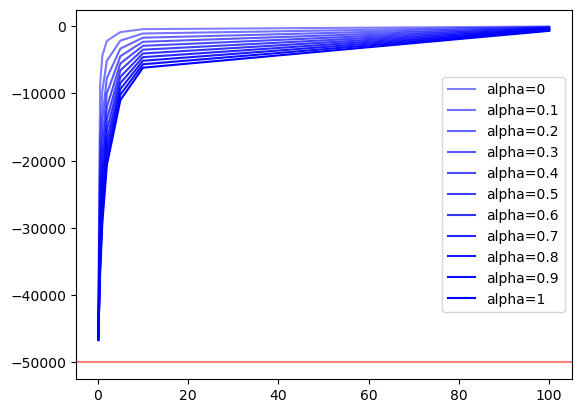

In [ ]:
plot_electricity_sensitivity([1000, 1000, 100, 10, 10, 0.92])

### Relative variation

In [ ]:
def electricity_price_p_impact(params):
    idx_1 = df.index[(df['land_size'] == str((params[0], params[1]))) & \
            (df['selling_price'] == params[1+1]) & \
                (df['max_yield'] == params[2+1]) & \
                    (df['max_Kc'] == params[3+1]) & \
                        (df['intermediate_yield'] == params[4+1]) & \
                            (df['alpha_price'] == params[5+1]) & \
                                (df['electricity_price'] == 100)]
    idx_2 = df.index[(df['land_size'] == str((params[0], params[1]))) & \
            (df['selling_price'] == params[1+1]) & \
                (df['max_yield'] == params[2+1]) & \
                    (df['max_Kc'] == params[3+1]) & \
                        (df['intermediate_yield'] == params[4+1]) & \
                            (df['alpha_price'] == params[5+1]) & \
                            (df['electricity_price'] == 0.1)]
    #print(df.loc[idx_1, 'q_opt_0'].values[0], df.loc[idx_2, 'q_opt_0'].values[0])
    return abs(df.loc[idx_1, 'q_opt_0'].values[0] - df.loc[idx_2, 'q_opt_0'].values[0])/abs(df.loc[idx_1, 'q_opt_0'].values[0])

p_sorted_product = sorted(product, key=electricity_price_p_impact)

In [ ]:
# np.savez("tmp/parameter_sorted_electricity_price_impact.npz",
#          sorted_product=sorted_product, p_sorted_product=p_sorted_product)

In [ ]:
electricity_price_p_impact(p_sorted_product[-1]), electricity_price_p_impact(p_sorted_product[0])

(np.float64(999.0000102567676), np.float64(5.674765233317045e-05))

In [ ]:
p_sorted_product[-1]

[100, 100, 0.1, 0.1, 10, 0.99, 0]

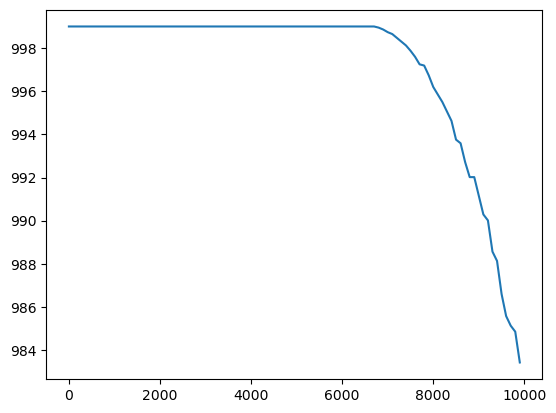

In [ ]:
plt.plot(range(1,10000,100), [electricity_price_p_impact(p_sorted_product[-i]) for i in range(1,10000,100)])

In [ ]:
electricity_price_p_impact(p_sorted_product[-1]), electricity_price_p_impact(p_sorted_product[-6700]), \
    electricity_price_p_impact(p_sorted_product[-6750]), electricity_price_p_impact(p_sorted_product[-7000])

(np.float64(999.0000102567676),
 np.float64(998.9999973291345),
 np.float64(998.9824236126877),
 np.float64(998.7364107650948))

In [ ]:
(np.array(p_sorted_product)[-int(len(p_sorted_product)/len(parameters_set['alpha_price'])):, -1] == 0).all(), len(p_sorted_product)/len(parameters_set['alpha_price'])

(np.True_, 6720.0)

In [ ]:
p_sorted_product[-6770:-6720]

[[1000, 1000, 0.1, 0.1, 10, 0.96, 0.5],
 [1000, 1000, 0.1, 0.1, 10, 0.95, 0.4],
 [1000, 1000, 0.1, 0.1, 10, 0.98, 1],
 [100, 100, 0.1, 0.1, 10, 0.98, 0.1],
 [100, 100, 0.1, 0.1, 10, 0.99, 0.2],
 [1000, 1000, 0.1, 0.1, 10, 0.91, 0.2],
 [1000, 1000, 0.1, 0.1, 10, 0.97, 0.6],
 [1000, 1000, 0.1, 0.1, 10, 0.98, 0.9],
 [1000, 1000, 0.1, 0.1, 10, 0.92, 0.2],
 [1000, 1000, 0.1, 0.1, 10, 0.96, 0.4],
 [1000, 1000, 0.1, 0.1, 10, 0.98, 0.8],
 [1000, 1000, 0.1, 0.5, 10, 0.97, 0.1],
 [1000, 1000, 0.1, 0.5, 10, 0.99, 0.3],
 [1000, 1000, 0.1, 0.1, 10, 0.95, 0.3],
 [1000, 1000, 0.1, 0.1, 10, 0.97, 0.5],
 [1000, 1000, 0.1, 0.1, 10, 0.98, 0.7],
 [1000, 1000, 0.1, 0.1, 10, 0.96, 0.3],
 [1000, 1000, 0.1, 0.1, 10, 0.97, 0.4],
 [1000, 1000, 0.1, 0.1, 10, 0.98, 0.6],
 [1000, 1000, 0.1, 1, 10, 0.99, 0.1],
 [1000, 1000, 1, 0.1, 10, 0.99, 0.1],
 [1000, 1000, 0.1, 0.5, 10, 0.98, 0.1],
 [1000, 1000, 0.1, 0.5, 10, 0.99, 0.2],
 [1000, 1000, 0.1, 0.1, 10, 0.9, 0.1],
 [1000, 1000, 0.1, 0.1, 10, 0.95, 0.2],
 [1000, 100

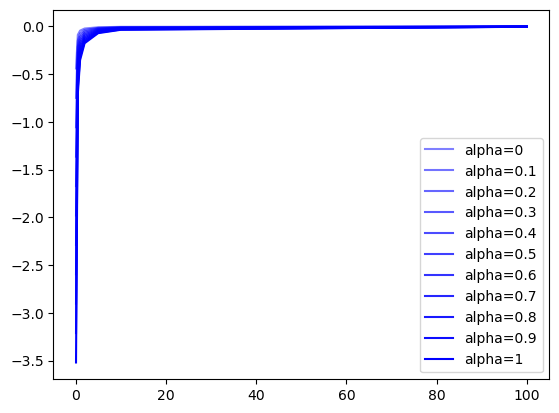

In [ ]:
plot_electricity_sensitivity([1000, 1000, 0.1, 0.1, 10, 0.96])

In [ ]:
p_sorted_product[-1]

[100, 100, 0.1, 0.1, 10, 0.99, 0]

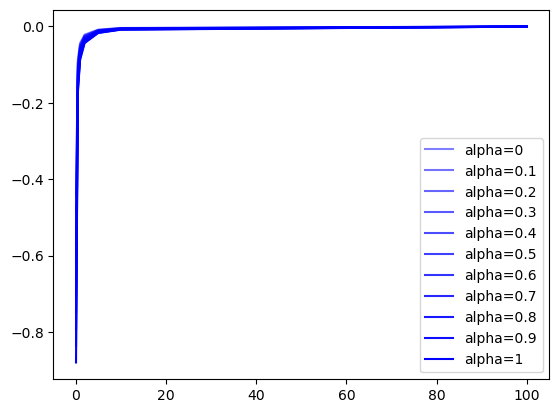

In [ ]:
plot_electricity_sensitivity([100, 100, 0.1, 0.1, 10, 0.99])

In [ ]:
p_sorted_product[0]

[10, 10, 100, 10, 0.1, 0.9, 1]

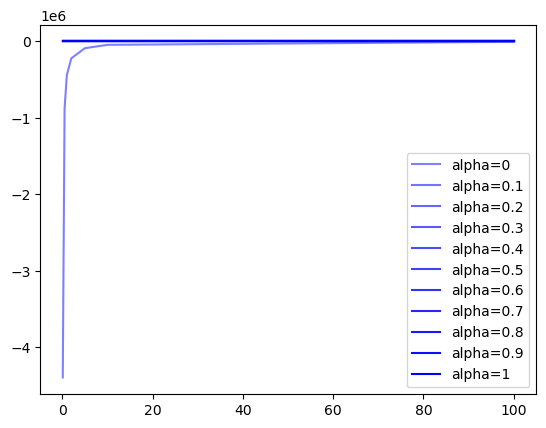

In [ ]:
plot_electricity_sensitivity([10, 10, 100, 10, 0.1, 0.9])

Highest variability:
- selling_price         = 0.1   (LOWEST)
- max_yield             = 0.1   (LOWEST)
- max_Kc                = 10    (HIGHEST)
- intermediate_yield    = 0.99  (HIGHEST)

Lowest variability:
- selling_price         = 100   (HIGHEST)
- max_yield             = 10    (HIGHEST)
- max_Kc                = 0.1   (LOWEST)
- intermediate_yield    = 0.9   (LOWEST)

Logical: there is a lot of variability when the price is flatten

# Study the influence of well distance on equilibrium with various parameters

What actually interests us when defining the cost is it's sensitivity to externalities (i.e. influence of the other well).

This means that we want the well distance to have a high impact on the cost and therefore the equilibrium.

In [6]:
parameters_set = {
    "land_size" : [(10,10), (100, 100), (500, 500)],
    "selling_price": [0.1, 0.5, 1, 5, 10, 50],
    "max_yield": [0.1, 0.5, 1, 2, 10],
    "max_Kc": [0.1, 0.5, 0.7, 1, 2, 10],
    "intermediate_yield": [0.9, 0.92, 0.95, 0.97, 0.98, 0.99],
    "alpha_price": [0, 0.2, 0.4, 0.6, 0.8, 1],
    "electricity_price": [0.1, 0.5, 1, 5, 10],
    "distance": [40, 80, 120, 200, 280, 360, 400]
}

In [7]:
dir, file = os.path.split(parameter_file)
name, ext = file.split('.')
new_parameter_file = dir + '/' + name + '_tmp' + '.' + ext

In [8]:
product_len = 1
for param in parameters_set.values():
    product_len *= len(param)
product_len

680400

In [ ]:
keys = list(parameters_set.keys())
values = list(parameters_set.values())

rows = list(itertools.product(*values))
df = pd.DataFrame(rows, columns=keys)

In [ ]:
df["q_opt_0"] = np.nan
df["q_opt_1"] = np.nan

In [9]:
Ymax_v_c_t = quad_cost._yield_max([0])
ETmax_v_c_t = quad_cost._local_evapotranspiration([0]).T
Y_q_v_c_t = quad_cost._yield_intermediate([0])
def _get_yield_response_to_water_coefficients(settings: Dict[str, Any]) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """ Coefficients of the quadratic function. """
    y = settings['max_yield']
    kc = settings['max_Kc']
    yi = settings['intermediate_yield']
    # Get yield data
    Ymax_v_c_t[0,0] = y             # [n_crop, horizon]
    ETmax_v_c_t[0,0] = kc*5         # [n_crop, horizon]
    Y_q_v_c_t[0,0] = yi             # [n_crop, horizon]
    # Safely inverse values
    inv_ETmax_v_c_t = np.where(ETmax_v_c_t !=0, 1/ETmax_v_c_t, 0)
    inv_quad_ETmax_v_c_t = inv_ETmax_v_c_t * inv_ETmax_v_c_t
    # Construct local coefficients
    d = ((1 - quad_cost.intermediate_irrigation_value)**2)
    a_yield_v_c_t = - Ymax_v_c_t * inv_quad_ETmax_v_c_t * (1 - Y_q_v_c_t) / d
    b_yield_v_c_t = 2* Ymax_v_c_t * inv_ETmax_v_c_t * (1 - Y_q_v_c_t) / d
    c_yield_v_c_t = Ymax_v_c_t * (1 - (1 - Y_q_v_c_t) / d)
    # Scale to obtain global coefficients
    if type(settings['land_size']) == str:
        land_surface = np.array(eval(settings['land_size']))
    else:
        land_surface = np.array(settings['land_size'])
    crop_surface = (land_surface * quad_cost.crop_repartition).T            # [n_agent, n_crops]
    inv_crop_surface = np.divide(1.0, crop_surface,
                                 out=np.zeros_like(crop_surface),
                                 where=crop_surface!=0)                     # [n_agent, n_crops]
    null_surface_mask = (crop_surface != 0).astype(float)                   # [n_agent, n_crops]
    a_yield_v_c_t = inv_crop_surface[:, :, None] * a_yield_v_c_t[None, :, :]
    b_yield_v_c_t = null_surface_mask[:, :, None] * b_yield_v_c_t[None, :, :]
    c_yield_v_c_t = crop_surface[:, :, None] * c_yield_v_c_t[None, :, :]
    return a_yield_v_c_t, b_yield_v_c_t, c_yield_v_c_t                      # [n_agent, n_crops, horizon]

def _compute_irrigation_cost_matrices(settings):
    # Get cost data
    a_yield_v_c_t, b_yield_v_c_t, _ = _get_yield_response_to_water_coefficients(settings)    # [n_agent, n_crop, horizon]
    # Arrange a in square diagonal matrices of size n_crops for all v,t
    diag_a_yield_v_c_t = [sp.diags(a_yield_v_c_t[v,:,0].flatten())
                          for v in range(quad_cost.n_agent)]
    # Arrange b in flat matrices of size n_crops for all v,t
    diag_b_yield_v_c_t = [b_yield_v_c_t[v,:,0].flatten().reshape(1, quad_cost.n_crops)
                    for v in range(quad_cost.n_agent)]
    # Form cost matrices
    spv = settings['selling_price']
    Ri_v = [- (spv * u2c.T  @ a_yield @ u2c)
                    for u2c, a_yield in
                    zip(quad_cost.input_to_crop_irrigation_v, diag_a_yield_v_c_t)]
    Li_v = [spv * b_yield @ u2c
                    for u2c, b_yield in
                    zip(quad_cost.input_to_crop_irrigation_v, diag_b_yield_v_c_t)]
    return Ri_v, Li_v

def _compute_irrigation_cost_matrix(settings):
    Ymax_v_c_t[0,0] = settings['max_yield']         # [n_crop, horizon]
    ETmax_v_c_t[0,0] = settings['max_Kc']*5         # [n_crop, horizon]
    # Safely inverse values
    inv_ETmax_v_c_t = np.where(ETmax_v_c_t !=0, 1/ETmax_v_c_t, 0)
    # Construct slope
    k_yield_v_c_t = Ymax_v_c_t * inv_ETmax_v_c_t    # [n_crop, horizon]
    # Extend it to all players
    if type(settings['land_size']) == str:
        land_surface = np.array(eval(settings['land_size']))
    else:
        land_surface = np.array(settings['land_size'])
    crop_surface = land_surface[:, None] * lin_cost.crop_repartition.T    # [n_agent, n_crops]
    null_surface_mask = (crop_surface != 0).astype(float)                 # [n_agent, n_crops]
    k_yield_v_c_t = null_surface_mask[:, :, None] * k_yield_v_c_t[None, :, :]
    diag_k_yield_v_c_t = [k_yield_v_c_t[v,:,0].flatten().reshape(1, lin_cost.n_crops)
                    for v in range(lin_cost.n_agent)]
    return [settings['selling_price'] * k_yield @ u2c
                     for u2c, k_yield in
                     zip(lin_cost.input_to_crop_irrigation_v, diag_k_yield_v_c_t)]

In [ ]:
pbar = tqdm(total=(len(df)), position=0, desc="Scenario")
alpha_step = len(parameters_set['electricity_price'])*len(parameters_set['distance'])

for distance in parameters_set["distance"]:
    # Update model
    shutil.copyfile(parameter_file, new_parameter_file)
    with open(new_parameter_file, 'r+') as f:
        data = json.load(f)
        # modify field
        shift = (distance - 40) // 80
        if (distance // 40) % 2 == 0:
            wells = [[0, 490 - 40*(shift + 1), 490],
                     [0, 530 + 40*shift,     490]]
        else:
            wells = [[0, 490 - 40*shift, 490],
                     [0, 530 + 40*shift, 490]]
        data['wells']['pos'] = wells
        # overwrite file
        f.seek(0)
        json.dump(data, f, indent=4)
        f.truncate()
    model = IrrigationSchedulingModel(new_parameter_file, boundary_condition="Constant Head")
    quad_cost = IrrigationSchedulingCostQuadraticYield(new_parameter_file, model, crops)
    # Model useful variables
    A = model.A
    Id_minus_A_inv = np.linalg.inv(np.eye(A.shape[0]) - A)
    B0, B1 = model.B_v
    Cinvt = model.C.T @ Id_minus_A_inv.T
    # Iterate over all other parameters
    df_dist = df[df["distance"] == distance]
    for idx, row in df_dist.iterrows():
        pbar.update(1)
        # Skip already computed values
        if not np.isnan(df.at[idx, "q_opt_0"]):
            continue
        # Construct quadratic and linear cost matrices
        Ri_v_quad, Li_v_quad = _compute_irrigation_cost_matrices(row)
        Li_v_lin = _compute_irrigation_cost_matrix(row)
        # Scale pumping cost
        ep = 10e-5 * row['electricity_price'] / quad_cost.extraction_cost_v[0]
        Rp_v  = ep * np.array(quad_cost.Rp_v)
        Rp_v_minus = ep * np.array(quad_cost.Rp_v_minus)
        Mp_v  = ep * np.array(quad_cost.Mp_v)
        Lp_v  = ep * np.array(quad_cost.Lp_v)
        # Iterate over varying quadratic reward importance
        for i_alpha, alpha in enumerate(parameters_set["alpha_price"]):
            # Construct cost matrices
            R_v = alpha * np.array(Ri_v_quad) + Rp_v
            L_v = alpha * np.array(Li_v_quad) + (1 - alpha) * np.array(Li_v_lin) + Lp_v
            # Compute equilibrium optimal command - Form cost matrices
            R00 = R_v[0,:,:] + B0.T @ Id_minus_A_inv.T @ Mp_v[0]
            R11 = R_v[1,:,:] + B1.T @ Id_minus_A_inv.T @ Mp_v[1]
            F = sp.block_array([
                [sp.csr_array(R00 + R00.T), sp.csr_array((Rp_v_minus[0] + B1.T @ Id_minus_A_inv.T @ Mp_v[0]).T)],
                [sp.csr_array((Rp_v_minus[1] + B0.T @ Id_minus_A_inv.T @ Mp_v[1]).T), sp.csr_array(R11 + R11.T)]
            ])
            f = np.vstack([
                (L_v[0] + Cinvt @ Mp_v[0]).T,
                (L_v[1] + Cinvt @ Mp_v[1]).T
            ])
            # Construct constraint matrices
            H = np.vstack([
                sp.block_diag(model.H_u_v).toarray(),
                # model.H_x @ (np.linalg.inv(np.eye(model.A.shape[0])-model.A)) @ sp.hstack(model.B_v)
            ])
            h = np.vstack([
                sp.vstack(model.h_u_v).toarray(),
                # model.h_x.toarray() - (np.linalg.inv(np.eye(model.A.shape[0])-model.A)) @ model.C
            ])
            # Find equilibrium
            u_s_0 = np.zeros((8, 1))
            dual_0 = np.zeros((H.shape[0], 1))
            U_opt, dual, E, out = fbrs(F, f, H, h, u_s_0, dual_0)
            # Write out result
            if df.at[idx+i_alpha*alpha_step, 'alpha_price'] != alpha:
                raise RuntimeError('wrong alpha indexation.')
            df.at[idx+i_alpha*alpha_step, 'q_opt_0'] = U_opt[0]
            df.at[idx+i_alpha*alpha_step, 'q_opt_1'] = U_opt[4]
            if (idx+i_alpha*alpha_step) % 1000 == 0:
                df.to_csv("tmp/equilibrium_cmd_dist.csv")
# print(df)

Scenario:   0%|          | 0/680400 [00:00<?, ?it/s]0.01s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
Scenario: 100%|█████████▉| 680383/680400 [2:36:22<00:01, 15.68it/s]   

In [ ]:
#df.to_csv("tmp/equilibrium_cmd_dist.csv")

In [10]:
df = pd.read_csv("tmp/equilibrium_cmd_dist.csv")

In [12]:
df_keyed = (
    df
    .set_index([
        "land_size",
        "selling_price",
        "max_yield",
        "max_Kc",
        "intermediate_yield",
        "alpha_price",
        "electricity_price",
        "distance"
    ])
    .sort_index()
)

df_keyed.at[('(10, 10)', 0.5, 0.1, 0.1, 0.99, 0.0, 0.1, 40),  "q_opt_0"]

np.float64(-714732.2107549349)

In [14]:
df_keyed = (
    df
    .set_index([
        "land_size",
        "selling_price",
        "max_yield",
        "max_Kc",
        "intermediate_yield",
        "alpha_price",
        "electricity_price",
        "distance"
    ])
    .sort_index()
)

def distance_impact(params):
    key = (str((params[0], params[1])), params[1+1], params[2+1], params[3+1],
           params[4+1], params[5+1], params[6+1])
    q40 = df_keyed.at[key + (40,), "q_opt_0"]
    q400 = df_keyed.at[key + (400,), "q_opt_0"]
    return abs(q40 - q400)/abs(q40)

product = [[l[0][0], l[0][1], l[1], l[2], l[3], l[4], l[5], l[6]]
           for l in list(itertools.product(parameters_set['land_size'],
                                           parameters_set['selling_price'],
                                           parameters_set['max_yield'],
                                           parameters_set['max_Kc'],
                                           parameters_set['intermediate_yield'],
                                           parameters_set['alpha_price'],
                                           parameters_set['electricity_price']))]

# Compute impact once per parameter combination (fast)
values = [(distance_impact(p), p) for p in product]
# Sort by impact
values_sorted = sorted(values, key=lambda x: x[0])
# Extract sorted products
sorted_product = [p for _, p in values_sorted]
sorted_impact = [i for i, _ in values_sorted]

In [15]:
sorted_impact[0], sorted_impact[-1]

(np.float64(0.0), np.float64(0.05956609235930703))

In [16]:
sorted_product[-10:]

[[100, 100, 0.1, 0.1, 10, 0.95, 0, 0.5],
 [100, 100, 0.1, 0.1, 10, 0.97, 0, 0.5],
 [100, 100, 0.1, 0.1, 10, 0.98, 0, 0.5],
 [100, 100, 0.1, 0.1, 10, 0.99, 0, 0.5],
 [500, 500, 0.1, 0.1, 10, 0.9, 0, 0.5],
 [500, 500, 0.1, 0.1, 10, 0.92, 0, 0.5],
 [500, 500, 0.1, 0.1, 10, 0.95, 0, 0.5],
 [500, 500, 0.1, 0.1, 10, 0.97, 0, 0.5],
 [500, 500, 0.1, 0.1, 10, 0.98, 0, 0.5],
 [500, 500, 0.1, 0.1, 10, 0.99, 0, 0.5]]

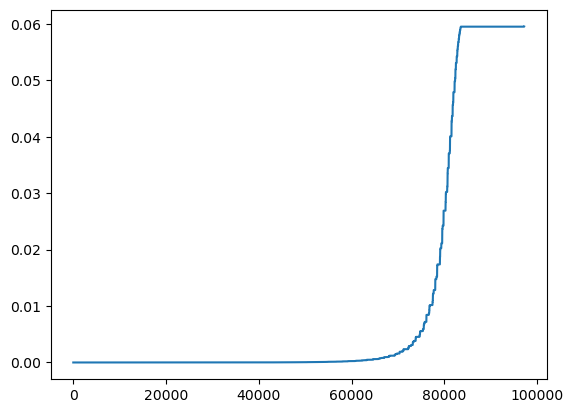

In [ ]:
plt.plot(sorted_impact)

In [ ]:
len(parameters_set['land_size'])*len(parameters_set['selling_price'])*\
    len(parameters_set['max_yield'])*len(parameters_set['max_Kc'])*\
        len(parameters_set['intermediate_yield'])*len(parameters_set['electricity_price'])

16200

In [ ]:
np.array(sorted_impact)[np.array(sorted_impact)>=0.05952], (np.array(sorted_product)[np.array(sorted_impact)>=0.05952, -2]==0).all()

(array([0.0595324 , 0.0595324 , 0.0595324 , ..., 0.05956609, 0.05956609, 0.05956609], shape=(13662,)),
 np.True_)

In [ ]:
(np.array(sorted_product)[-13662:, -2]==0).all()

np.True_

In [ ]:
np.array(sorted_impact)[np.array(sorted_product)[:, -2] == 1][-1], np.array(sorted_product)[np.array(sorted_product)[:, -2] == 1][-1]

(np.float64(0.05946058291893519),
 array([5.0e+02, 5.0e+02, 1.0e-01, 1.0e-01, 1.0e+01, 9.9e-01, 1.0e+00, 1.0e+01]))

- High electricity price (10)
- Almost flat yield profit (low yield, high irrigation need, high saturation, low selling price)

In [ ]:
np.array(sorted_impact)[np.array(sorted_product)[:, -2] == 1][-10:], np.array(sorted_product)[np.array(sorted_product)[:, -2] == 1][-10:]

(array([0.05910284, 0.05917405, 0.05917405, 0.05917405, 0.05917405, 0.05924541, 0.05931697, 0.05938868, 0.05938869, 0.05946058]),
 array([[5.0e+02, 5.0e+02, 1.0e-01, 1.0e-01, 1.0e+01, 9.7e-01, 1.0e+00, 5.0e+00],
        [1.0e+02, 1.0e+02, 1.0e-01, 1.0e-01, 1.0e+01, 9.9e-01, 1.0e+00, 1.0e+01],
        [5.0e+02, 5.0e+02, 1.0e-01, 1.0e-01, 1.0e+01, 9.5e-01, 1.0e+00, 1.0e+01],
        [5.0e+02, 5.0e+02, 1.0e-01, 5.0e-01, 1.0e+01, 9.9e-01, 1.0e+00, 1.0e+01],
        [5.0e+02, 5.0e+02, 5.0e-01, 1.0e-01, 1.0e+01, 9.9e-01, 1.0e+00, 1.0e+01],
        [5.0e+02, 5.0e+02, 1.0e-01, 1.0e-01, 1.0e+01, 9.8e-01, 1.0e+00, 5.0e+00],
        [5.0e+02, 5.0e+02, 1.0e-01, 1.0e-01, 1.0e+01, 9.7e-01, 1.0e+00, 1.0e+01],
        [5.0e+02, 5.0e+02, 1.0e-01, 1.0e-01, 1.0e+01, 9.9e-01, 1.0e+00, 5.0e+00],
        [5.0e+02, 5.0e+02, 1.0e-01, 1.0e-01, 1.0e+01, 9.8e-01, 1.0e+00, 1.0e+01],
        [5.0e+02, 5.0e+02, 1.0e-01, 1.0e-01, 1.0e+01, 9.9e-01, 1.0e+00, 1.0e+01]]))

In [ ]:
(np.array(sorted_product)[:, [3, 4, -2]] == [1,1,1]).all(axis=1)

array([False, False, False, ..., False, False, False], shape=(97200,))

In [ ]:
np.array(sorted_impact)[(np.array(sorted_product)[:, [3, 4, -2]] == [1,1,1]).all(axis=1)][-1], np.array(sorted_product)[(np.array(sorted_product)[:, [3, 4, -2]] == [1,1,1]).all(axis=1)][-1]

(np.float64(0.026913531266961024),
 array([5.0e+02, 5.0e+02, 1.0e-01, 1.0e+00, 1.0e+00, 9.9e-01, 1.0e+00, 1.0e+01]))

Electricity price much higher than selling price (10>>0.1)

CCL: To have variability, we need either electricity price higher than selling price or almost flat crop reward.

In [19]:
def plot_distance_sensitivity(params):
    fig, ax = plt.subplots(1,1)
    for alpha in parameters_set['alpha_price']:
        key = (str((params[0], params[1])), params[1+1], params[2+1], params[3+1],
           params[4+1], alpha, params[6+1])
        ax.plot(parameters_set['distance'], df_keyed.loc[key, "q_opt_0"].values,
                label=f"alpha={alpha}", color='b', alpha=alpha*0.5+0.5)
        ax.text(parameters_set['distance'][-1]-25, df_keyed.loc[key, "q_opt_0"].values[-1]+5,
                f"-{((df_keyed.loc[key, "q_opt_0"].values[0]-df_keyed.loc[key, "q_opt_0"].values[-1])/\
                    abs(df_keyed.loc[key, "q_opt_0"].values[0])*100).round(2)}%")
        # print(((df_keyed.loc[key, "q_opt_0"].values[0]-df_keyed.loc[key, "q_opt_0"].values[-1])/\
        #             abs(df_keyed.loc[key, "q_opt_0"].values[0])*100).round(2))
    qmax = -params[3+1]*5*params[0]
    if min(ax.get_ybound()) <= qmax:
        ax.axhline(qmax, color='r', alpha=0.5)
    ax.legend()

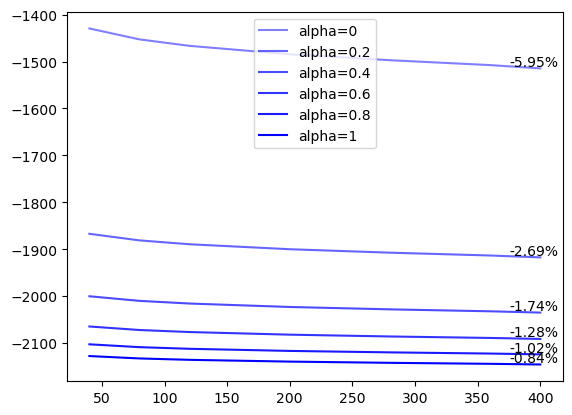

In [21]:
plot_distance_sensitivity([500, 500, 0.1, 1, 1, 0.95, 1, 10])

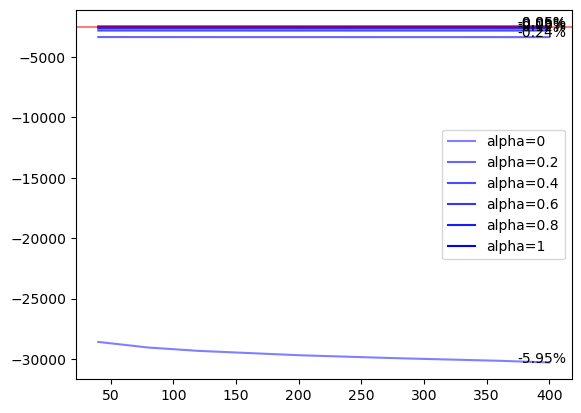

In [22]:
plot_distance_sensitivity([500, 500, 0.1, 1, 1, 0.95, 1, 0.5])

#### Change conductivity (decreased)

In [368]:
params = {
    "land_size" : (500, 500),
    "selling_price": 0.1,
    "max_yield": 1,
    "max_Kc": 1,
    "intermediate_yield": 0.95,
    "alpha_price": 1,
    "electricity_price": 0.5,
    "distance": [40, 80, 120, 200, 280, 360, 400]
}

# with open(new_parameter_file, 'r+') as f:
#     data = json.load(f)
#     # modify field
#     data['land']['surface'] = list(params['land_size'])
#     data['costs']['selling_crop_price'] = [params['selling_price'], params['selling_price'], params['selling_price'], params['selling_price']]
#     data['crops']['corn']['Y_max_t'][0] = params['max_yield']
#     data['crops']['corn']['Kc_t'] = [params['max_Kc'], params['max_Kc']]
#     data['crops']['corn']['Y_intermediate_t'][0] = params['intermediate_yield']
#     data['costs']['extraction_cost'] = [params['electricity_price'], params['electricity_price']]
#     # overwrite file
#     f.seek(0)
#     json.dump(data, f, indent=4)
#     f.truncate()
# model = IrrigationSchedulingModel(new_parameter_file, boundary_condition="Constant Head")
# quad_cost = IrrigationSchedulingCostQuadraticYield(new_parameter_file, model, crops)

distance_sensitivity_low_k = []
for distance in parameters_set["distance"]:
    distance_sensitivity_low_k.append([])
    with open(new_parameter_file, 'r+') as f:
        data = json.load(f)
        # modify field
        shift = (distance - 40) // 80
        if (distance // 40) % 2 == 0:
            wells = [[0, 490 - 40*(shift + 1), 490],
                        [0, 530 + 40*shift,     490]]
        else:
            wells = [[0, 490 - 40*shift, 490],
                        [0, 530 + 40*shift, 490]]
        data['wells']['pos'] = wells
        data['physical']['hk'] = 0.1
        # overwrite file
        f.seek(0)
        json.dump(data, f, indent=4)
        f.truncate()
    model = IrrigationSchedulingModel(new_parameter_file, boundary_condition="Constant Head")
    quad_cost = IrrigationSchedulingCostQuadraticYield(new_parameter_file, model, crops)
    # Model useful variables
    A = model.A
    Id_minus_A_inv = np.linalg.inv(np.eye(A.shape[0]) - A)
    B0, B1 = model.B_v
    Cinvt = model.C.T @ Id_minus_A_inv.T
    # Construct quadratic and linear cost matrices
    Ri_v_quad, Li_v_quad = _compute_irrigation_cost_matrices(params)
    Li_v_lin = _compute_irrigation_cost_matrix(params)
    # Scale pumping cost
    Rp_v  = np.array(quad_cost.Rp_v)
    Rp_v_minus = np.array(quad_cost.Rp_v_minus)
    Mp_v  = np.array(quad_cost.Mp_v)
    Lp_v  = np.array(quad_cost.Lp_v)
    # Iterate over varying quadratic reward importance
    for i_alpha, alpha in enumerate(parameters_set["alpha_price"]):
        # Construct cost matrices
        R_v = alpha * np.array(Ri_v_quad) + Rp_v
        L_v = alpha * np.array(Li_v_quad) + (1 - alpha) * np.array(Li_v_lin) + Lp_v
        # Compute equilibrium optimal command - Form cost matrices
        R00 = R_v[0,:,:] + B0.T @ Id_minus_A_inv.T @ Mp_v[0]
        R11 = R_v[1,:,:] + B1.T @ Id_minus_A_inv.T @ Mp_v[1]
        F = sp.block_array([
            [sp.csr_array(R00 + R00.T), sp.csr_array((Rp_v_minus[0] + B1.T @ Id_minus_A_inv.T @ Mp_v[0]).T)],
            [sp.csr_array((Rp_v_minus[1] + B0.T @ Id_minus_A_inv.T @ Mp_v[1]).T), sp.csr_array(R11 + R11.T)]
        ])
        f = np.vstack([
            (L_v[0] + Cinvt @ Mp_v[0]).T,
            (L_v[1] + Cinvt @ Mp_v[1]).T
        ])
        # Construct constraint matrices
        H = np.vstack([
            sp.block_diag(model.H_u_v).toarray(),
            # model.H_x @ (np.linalg.inv(np.eye(model.A.shape[0])-model.A)) @ sp.hstack(model.B_v)
        ])
        h = np.vstack([
            sp.vstack(model.h_u_v).toarray(),
            # model.h_x.toarray() - (np.linalg.inv(np.eye(model.A.shape[0])-model.A)) @ model.C
        ])
        # Find equilibrium
        u_s_0 = np.zeros((8, 1))
        dual_0 = np.zeros((H.shape[0], 1))
        U_opt, dual, E, out = fbrs(F, f, H, h, u_s_0, dual_0)
        # Write out result
        distance_sensitivity_low_k[-1].append(U_opt[0])
distance_sensitivity_low_k = np.array(distance_sensitivity_low_k)

In [370]:
np.array(distance_sensitivity_low_k)[:,1,:].shape

(7, 1)

In [371]:
params['max_Kc']

1

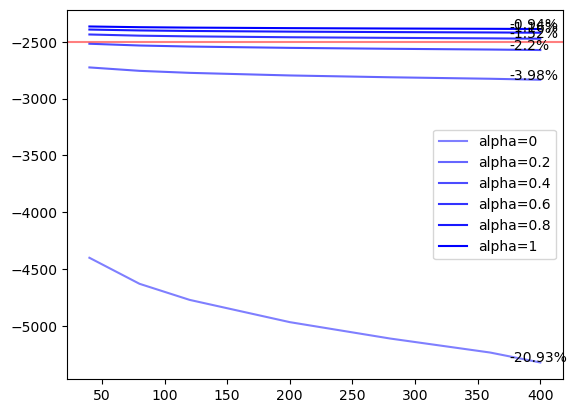

In [372]:
fig, ax = plt.subplots(1,1)
for i, alpha in enumerate(parameters_set['alpha_price']):
    ax.plot(parameters_set['distance'], distance_sensitivity_low_k[:,i,:],
            label=f"alpha={alpha}", color='b', alpha=alpha*0.5+0.5)
    ax.text(parameters_set['distance'][-1]-25, distance_sensitivity_low_k[-1,i,:]+5,
                    f"-{((distance_sensitivity_low_k[0,i,0]-distance_sensitivity_low_k[-1,i,0])/\
                        abs(distance_sensitivity_low_k[0,i,0])*100).round(2)}%")
qmax = -params['max_Kc']*5*params['land_size'][0]
if min(ax.get_ybound()) <= qmax:
    ax.axhline(qmax, color='r', alpha=0.5)
ax.legend()

In [373]:
((distance_sensitivity_low_k[0,-1,0] - distance_sensitivity_low_k[-1,-1,0])/-distance_sensitivity_low_k[0,-1,0])*100

np.float64(0.9383486319466424)

In [374]:
key = (params['land_size'], params['selling_price'], params['max_yield'], params['max_Kc'],
           params['intermediate_yield'], params['alpha_price'], params['electricity_price'])
((df_keyed.loc[key, "q_opt_0"].values[0]-df_keyed.loc[key, "q_opt_0"].values[-1])/\
            abs(df_keyed.loc[key, "q_opt_0"].values[0])*100)

np.float64(0.04871792232683903)

Reducing $k$ increases sensitivity